In [5]:
from main import *

In [6]:
def run_experiment(
        n=1000, 
        d=50, 
        prop_noised=0.1, 
        b_noise_scale=0.2, 
        teacher_noise_scale=0.1,
        x0_scale=50,
        iters=5000,
        seed=1
    ):
    # Generate system
    rng = np.random.default_rng(seed=seed)
    n_noised = int(n * prop_noised)
    A, x, b = get_system(rng, n, d)

    noised_indices = rng.choice(n, size=n_noised, replace=False)
    b_noised = b
    b_noised[noised_indices] += rng.normal(scale=b_noise_scale, size=n_noised)

    x_teacher = x + rng.normal(size=d, scale=teacher_noise_scale)

    x0 = rng.normal(scale=x0_scale, size=d)

    common_params = dict(
        x0=x0,
        A=A,
        b=b_noised,
        x_sol=x,
        batch_size=n,
        maxiter=iters
    )

    sols = [
        MillerOpt(**common_params, teacher=x_teacher, noised_indices=noised_indices),
        RandomizedKaczmarz(**common_params),
    ]

    for sol in sols:
        sol.solve()

    comparison = Comparison(sols)
    comparison.plot_parameter_errors(
        title=f"Comparing Kaczmarz convergence\n(batch size {common_params["batch_size"]}, noise std {b_noise_scale})",
        logx=True,
        logy=False
    )

    bound_diff_eq = np.array(sols[0].diagnostics["bound_diff_eq"])

    plt.plot(bound_diff_eq[:, 0], bound_diff_eq[:, 1], color="tab:green", label="Bound (DE)", lw=1)
    plt.axhline(sols[0].diagnostics["bound_diff_eq_floor"], label="Floor (DE)", ls="--", color="tab:green", lw=1)

    # plt.plot(sols[0].diagnostics["bounds"], color="tab:red", label="Bound (PP)")
    iter_range = np.arange(iters)
    e0 = sols[0].parameter_errors[0]
    bound_peter_paul_floor = sols[0].diagnostics["bound_peter_paul_floor"]
    plt.plot(iter_range, (1 - sols[0].alpha / 2)**iter_range * (e0 - bound_peter_paul_floor) + bound_peter_paul_floor, color="tab:red", label="Bound (PP)", lw=1)
    plt.axhline(bound_peter_paul_floor, color="tab:red", ls="--", label="Floor (PP)", lw=1)

    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

    print(f"alpha: {sols[0].alpha}")
    print(f"beta:  {sols[0].beta}")
    print(f"gamma: {sols[0].gamma}")

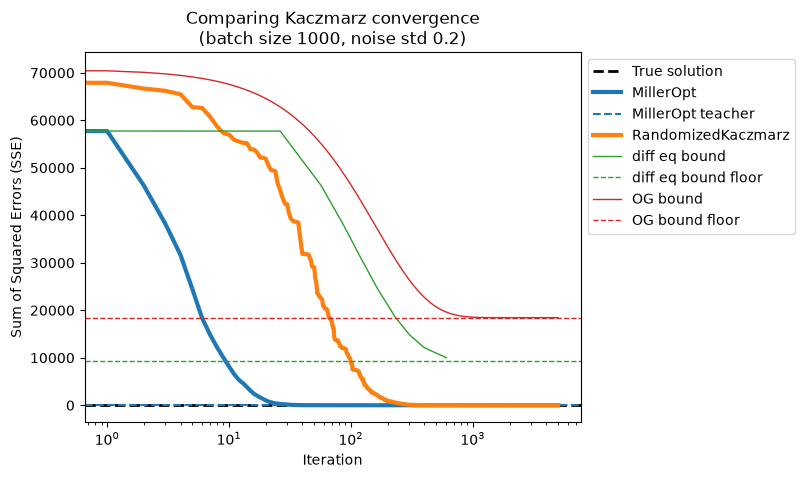

alpha: 0.012495345983451986
beta:  1.1980561218332744
gamma: 0.36012237769080185


In [7]:
run_experiment()

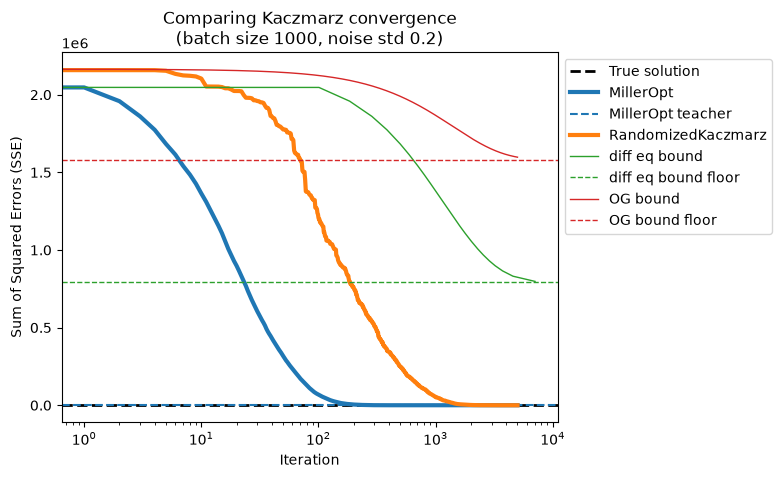

alpha: 0.0014232448211118627
beta:  1.265305358628908
gamma: 0.3126811262515957


In [10]:
run_experiment(
    n=1000, 
    d=200, 
    prop_noised=0.1, 
    b_noise_scale=0.2, 
    teacher_noise_scale=0.1,
    x0_scale=100,
    iters=5000,
    seed=2
)